# Beyond: calibrate before 2023, score March 2023, and read the reverse stress as a multiplier

- **Level:** 4, Beyond the state of the art
- **Prerequisites:** notebooks 02, 04, 06 and 07 of this topic
- **Reading time:** about 45 minutes

## Objectives

By the end of this notebook you can:

- state the claim BS-11 of the product (reverse liquidity stress as a run-off multiplier, with a refusal rule, scored against a labelled run) and say what the state of the art leaves open;
- reproduce the multiplier of the three bases with the engine and check that it is a threshold, that the engine refuses what it cannot bracket and that a step in the survival period does not break the round trip;
- see the leakage guard at work (calibrate before 2023, score on 2023) and what the scoring says;
- read the multiplier as a distance: how far the run of Silicon Valley Bank was from the 30-day target.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==0.9.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.9.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

Five committed documents of case C16, all in `data/derived/C16/` (real FDIC call-report aggregates of the bank that failed on 2023-03-10 up to 2022-12-31, synthetic behaviour and deposits, licence class `mirror-allowed`):

- `reverse-stress.json`: the multiplier of the three bases at a target of 30 days, with the curve, the round trip and the refusal.
- `fast-run.json`: the fast-run variant and its scoring against the runs of Table A.1 (BCBS, 2023).
- `models-svb-liquidity.json`: the calibration split and the depositor generator with its known truth.
- `list-adverse.json` and `list-extreme.json`: the ladders of the two LiST bases.

Amounts are in USD thousands. The observed run is the one of Silicon Valley Bank, 85% of the deposits in 2 days (BCBS, 2023, Table A.1; Federal Reserve, 2023).

In [2]:
# Load the five committed documents (the notebook sits three folders below the repository root)
ROOT = Path("../../..").resolve()
documents = {}
for name in ("reverse-stress", "fast-run", "models-svb-liquidity", "list-adverse", "list-extreme"):
    documents[name] = json.loads((ROOT / "data" / "derived" / "C16" / f"{name}.json").read_text(encoding="utf-8"))
    print(name, "| baked by riskvalidation", documents[name]["provenance"]["riskvalidation_version"], "| installed", rv.__version__)

reverse_doc = documents["reverse-stress"]
bases = {base["base_id"]: base for base in reverse_doc["outputs"]["bases"]}
conventions = reverse_doc["outputs"]["conventions"]
rows = {row["variant"]: row for row in conventions["variant_scenarios"]["rows"]}
target = reverse_doc["outputs"]["target"]["days"]
print("target (days):", target, "| bases:", list(bases))

reverse-stress | baked by riskvalidation 0.9.0 | installed 0.9.0
fast-run | baked by riskvalidation 0.9.0 | installed 0.9.0
models-svb-liquidity | baked by riskvalidation 0.9.0 | installed 0.9.0
list-adverse | baked by riskvalidation 0.9.0 | installed 0.9.0
list-extreme | baked by riskvalidation 0.9.0 | installed 0.9.0
target (days): 30 | bases: ['list-adverse', 'list-extreme', 'fast-run']


## Method

### Step 1: the multiplier of the three bases

The reverse stress asks for the smallest multiplier $m^*$ of the daily run-off rates (each rate kept at most 1) at which the survival period falls to the target $T$ (notebook 06):

$$m^* = \min\{\, m \in [1, m_{\max}] : \mathrm{SP}(m) \le T \,\}, \qquad \mathrm{SP}(m^*) \le T < \mathrm{SP}(m^* - 10^{-6})$$

The next cell rebuilds the three base scenarios from the committed segments (the fast run with the rate calibrated on the rows before 2023, as in notebook 04), builds the effective CBC of notebook 06, and solves at the target of the document. It compares with the committed solutions and prints the reason when the engine refuses.

In [3]:
# Rebuild the three bases, build the effective CBC and solve for the multiplier at the target of the document
from riskvalidation.liquidity.reverse import max_multiplier, solve_multiplier, survival_vs_multiplier
from riskvalidation.liquidity.runoff import LIST_PARAMETERS, TABLE_A1
from riskvalidation.liquidity.scenarios import Scenario, anchor_from_observation, compose_scenario, fast_run_scenario, list_scenario
from riskvalidation.validation.liquidity import reverse_stress_round_trip

pre_2023 = [run for run in TABLE_A1 if run.year < 2023]
fit = fast_run_scenario(pre_2023, "maximum-implied-daily-rate", scored=True)

built = {}
for base_id, severity in (("list-adverse", "adverse"), ("list-extreme", "extreme"), ("fast-run", "adverse")):
    lad = documents[base_id]["outputs"]["path"]["ladder"]
    row = rows[base_id]
    segments = {s["segment"]: (s["list_class"], s["opening_balance"]) for s in lad["segments"]}
    if base_id == "fast-run":
        rest = compose_scenario(row["scenario_family"], row["phase"], list_scenario(severity), {k: v for k, v in segments.items() if k != "non-operational-corporate"}, row["horizon_days"])
        corporate = compose_scenario(row["scenario_family"], row["phase"], fit, {"non-operational-corporate": ("concentrated-uninsured", segments["non-operational-corporate"][1])}, row["horizon_days"])
        by_id = {s.segment_id: s for s in (*rest.segments, *corporate.segments)}
        scenario = Scenario(row["scenario_family"], row["phase"], row["horizon_days"], tuple(by_id[k] for k in segments))
    else:
        scenario = compose_scenario(row["scenario_family"], row["phase"], list_scenario(severity), segments, row["horizon_days"])
    contractual = np.array(lad["total_outflows"]) - scenario.outflows().sum(axis=0)
    effective_cbc = np.array(lad["cbc_total"]) + np.cumsum(lad["total_inflows"]) - np.cumsum(contractual)
    built[base_id] = (scenario, effective_cbc)

words = {"solved": "solved", "refused": "refused"}
for base_id, (scenario, effective_cbc) in built.items():
    answer = solve_multiplier(scenario, effective_cbc, target)
    committed = bases[base_id]["solved"]
    print(f"{base_id:13s} | cap: {max_multiplier(scenario):9.4f} | {words[answer.status]} | m* = {answer.multiplier} | committed: {committed['multiplier']} | equal: {answer.multiplier == committed['multiplier']}")
    if answer.status == "refused":
        print("   ", committed["refusal_reason"]["en"])

list-adverse  | cap:  145.2346 | solved | m* = 2.118175 | committed: 2.118175 | equal: True
list-extreme  | cap:   93.8765 | solved | m* = 1.383141 | committed: 1.383141 | equal: True
fast-run      | cap:   18.4303 | refused | m* = None | committed: None | equal: True
    The target of 30 days is not below the horizon of 5 days, so a survival period under it cannot be separated from surviving the horizon: no bracket exists.


### Step 2: a step in the survival period

The survival period is an integer day, and a CBC that grows over the first days can make it jump past the target: no multiplier then gives exactly the target. The engine returns the **threshold** (the smallest $m$ with $\mathrm{SP}(m) \le T$), reports the survival period at it and just below it, and the round-trip test accepts the step as long as the target is reached at $m^*$ and not just below. The fast-run base has a horizon of 5 days, so the target of the document (30 days) is refused; targets under the horizon are solved. The next cell asks the fast-run base for targets of 5, 4, 3 and 1 days (an exploration, not committed rows) and runs the round-trip test on each answer.

In [4]:
# Targets of 5, 4, 3 and 1 days on the fast-run base, and the round-trip test of each answer
scenario, effective_cbc = built["fast-run"]
print("horizon of the base (days):", scenario.horizon, "| cap:", round(max_multiplier(scenario), 6))
for days in (5, 4, 3, 1):
    answer = solve_multiplier(scenario, effective_cbc, days)
    if answer.status == "refused":
        print(f"target {days} | {words[answer.status]} | m* = {answer.multiplier}")
        continue
    test = reverse_stress_round_trip(answer.multiplier, answer.survival_at_multiplier, days, 0.0, survival_just_below=answer.survival_just_below)
    print(f"target {days} | {words[answer.status]} | m* = {answer.multiplier} | survival at m*: {answer.survival_at_multiplier} | just below: {answer.survival_just_below.day} | round trip: {test.statistic} {test.light.value}")

horizon of the base (days): 5 | cap: 18.430329
target 5 | refused | m* = None
target 4 | solved | m* = 2.06764 | survival at m*: 4 | just below: 5 | round trip: 0.0 green
target 3 | solved | m* = 2.669936 | survival at m*: 1 | just below: 4 | round trip: 0.0 green
target 1 | solved | m* = 2.669936 | survival at m*: 1 | just below: 4 | round trip: 0.0 green


### Step 3: calibrate before 2023, score on March 2023

The fast-run rate is a statistic of the implied daily rates of Table A.1, $q_i = 1-(1-F_i)^{1/n_i}$, and the rule of the document is the maximum. The protocol is leakage-safe by construction: the calibration uses the four rows dated before 2023, the engine refuses a 2023 row in a scored call, and the 2023 rows are what the variant is scored against; the observation of Silicon Valley Bank is a labelled anchor (`forecast_claim` is false), never a forecast. The next cell shows the calibration, the refusal and the committed scoring of the variant on the rows that its 5-day ladder can score.

In [5]:
# The calibration on the rows before 2023, the refusal of a 2023 row and the committed scoring of the fast run
calibration = documents["models-svb-liquidity"]["fit"]["calibration"]
print("calibrated on:", calibration["split"]["calibrated_on"])
print("scored on:", calibration["split"]["scored_on"])
anchor = anchor_from_observation(0.85, 2)
print("anchor of the engine (implied daily rate, forecast claim):", round(anchor["implied_daily_rate"], 6), anchor["forecast_claim"])
print("fitted rate:", round(fit.daily_rate, 8), "| committed:", round(calibration["fitted_daily_rate"]["value"], 8), "| anchor forecast claim:", calibration["anchor"]["forecast_claim"])
try:
    fast_run_scenario(list(TABLE_A1), "maximum-implied-daily-rate", scored=True)
except ValueError:
    print("a scored call with a 2023 row is refused by the engine (ValueError)")

roles = {"calibration": "calibration", "scored": "scored"}
print(f"{'row':22s}{'role':>14s}{'observed':>14s}{'modelled':>14s}{'error':>10s}")
for entry in documents["fast-run"]["outputs"]["scoring"]["table_a1_scoring"]:
    if entry["modelled_share"] is not None:
        print(f"{entry['row_id']:22s}{roles[entry['role']]:>14s}{entry['observed_share']:14.2f}{entry['modelled_share']:14.4f}{entry['error']:10.4f}")
for entry in documents["fast-run"]["tests"]:
    if entry["test_id"] == "liq.runoff_adequacy_back_test":
        print("back-test:", entry["segment"], "| ratio:", round(entry["statistic"], 6), entry["light"], "| baked by", documents["fast-run"]["provenance"]["riskvalidation_version"])

calibrated on: ['icesave-2008', 'northern-rock-2007', 'wamu-2008', 'indymac-2008']
scored on: ['svb-2023', 'first-republic-2023', 'svb-uk-2023', 'credit-suisse-2023', 'signature-2023']
anchor of the engine (implied daily rate, forecast claim): 0.612702 False
fitted rate: 0.05425839 | committed: 0.05425839 | anchor forecast claim: False
a scored call with a 2023 row is refused by the engine (ValueError)
row                             role      observed      modelled     error
svb-2023                      scored          0.85        0.1708    0.6792
svb-uk-2023                   scored          0.30        0.1263    0.1737
signature-2023                scored          0.20        0.1263    0.0737
northern-rock-2007       calibration          0.20        0.2528   -0.0528
back-test: board-stated-share | ratio: 0.200976 red | baked by 0.9.0
back-test: call-report-dep | ratio: 0.214124 red | baked by 0.9.0


## State of the art

- **Forward scenarios.** The ECB's liquidity stress test of 2019 fixes the scenarios first (smooth daily compounding rates by severity) and reports the survival period they give (ECB, 2019, methodological note and results annex).
- **Variety of scenarios.** Principle 10 of the Basel principles asks for stress tests in many scenarios, individually and in combination (BCBS, 2008); it does not say how to find the scenario that breaks a given bank.
- **The 2023 evidence.** The report on the 2023 turmoil says the speed assumptions were reset by runs such as 85% of the deposits in 2 days and lists as open questions metrics such as a five-day forward counterbalancing capacity and the survival period (BCBS, 2023); the Federal Reserve found the bank's internal liquidity stress test relied on non-comparable peer benchmarks (Federal Reserve, 2023).
- **Reverse stress in the research.** The research dossier lists reverse liquidity stress as the last rung of its liquidity model ladder ("the run-off multiplier at which the survival period falls below a target, for example 30 days") with no measured case, and found no tool that implements it (UNVERIFIED beyond the dossier's search).

## Beyond the state of the art

**BS-11**, as stated in the SDD: the product answers the reverse question with a number that has three properties the state of the art leaves open.

1. **A threshold, not an estimate.** The multiplier of the daily run-off rates at which the survival period first falls to the target, capped so that no rate exceeds 1, with the survival period at it and just below it (steps 1 and 2);
2. **A refusal rule.** A target that cannot be bracketed (not below the horizon, already reached at the base, unreachable under the cap) is refused with its reason and no number is returned (step 1, the fast run; step 2);
3. **A guarded, labelled run.** The fast-run base is calibrated on the rows before 2023 only, the engine refuses a 2023 row in a scored call, and the 2023 rows score it, with the observation of Silicon Valley Bank as an anchor and never a forecast (step 3).

The evidence is the computation above, which reproduces the committed documents with the engine. What it adds is a way to read the distance between a stress test and a real run: the multiplier. The next cell computes that distance. For each LiST base, $m_{\mathrm{SVB}}$ is the multiplier that takes the rate of the uninsured corporate class to the implied daily rate of Silicon Valley Bank, $m_{\mathrm{SVB}} = q_{\mathrm{SVB}} / q_{\text{class}}$; the engine gives the survival period under it, and the ratio $m_{\mathrm{SVB}} / m^*$ tells how many times farther the 2023 run is than the 30-day target.

In [6]:
# The multiplier that takes the LiST rate of the uninsured corporate class to the rate of SVB, against the threshold multiplier
svb = next(run for run in TABLE_A1 if run.row_id == "svb-2023")
corporate = "non-operational-non-financial-corporates"
distance = {}
print("implied daily rate of SVB:", round(svb.implied_daily_rate, 6))
for base_id, severity in (("list-adverse", "adverse"), ("list-extreme", "extreme")):
    scenario, effective_cbc = built[base_id]
    m_star = solve_multiplier(scenario, effective_cbc, target).multiplier
    m_svb = svb.implied_daily_rate / LIST_PARAMETERS[severity]["open_maturity"][corporate]
    at_svb = survival_vs_multiplier(scenario, effective_cbc, np.array([1.0, m_svb]))[1]
    distance[base_id] = (m_star, m_svb)
    print(f"{base_id:13s} | m* = {m_star} | m_SVB = {m_svb:.4f} | cap: {max_multiplier(scenario):.4f} | survival period at m_SVB (day): {at_svb.day} | m_SVB / m* = {m_svb / m_star:.2f}")

implied daily rate of SVB: 0.612702
list-adverse  | m* = 2.118175 | m_SVB = 88.9855 | cap: 145.2346 | survival period at m_SVB (day): 1 | m_SVB / m* = 42.01
list-extreme  | m* = 1.383141 | m_SVB = 57.5183 | cap: 93.8765 | survival period at m_SVB (day): 1 | m_SVB / m* = 41.59


The known-truth check of the estimator behind the fast run is committed too: the depositor generator of the models document, with an exact truth, was verified against 20,000 seeded draws, and the test `liq.runoff_vs_generator_truth` of the fast-run document reads its result (notebook 04 reruns a small version of it). The last cell prints both and draws the answer: on the left, the survival period against the multiplier for the three bases with the thresholds marked; on the right, the threshold multiplier of each LiST base against the multiplier of the 2023 run, on a logarithmic axis.

generator verification: draws, largest error, standard error, within error: 20000 0.00026 0.000484 True
test row: largest distance in standard errors and light: 0.5369 green


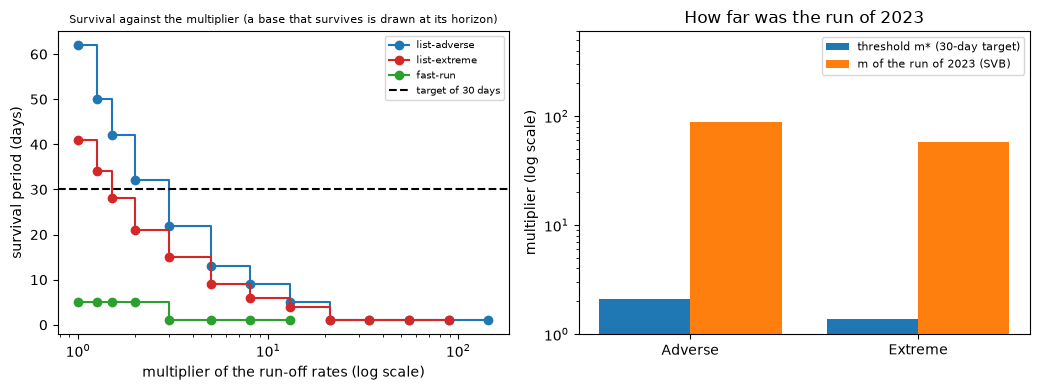

In [7]:
# The committed known-truth check, then the survival curves with their thresholds and the distance to the run of 2023
verification = documents["models-svb-liquidity"]["fit"]["generator"]["verification"]
truth_row = next(entry for entry in documents["fast-run"]["tests"] if entry["test_id"] == "liq.runoff_vs_generator_truth")
print("generator verification: draws, largest error, standard error, within error:", verification["n_draws"], round(verification["max_abs_error"], 6), round(verification["mc_standard_error"], 6), verification["within_error"])
print("test row: largest distance in standard errors and light:", round(truth_row["statistic"], 4), truth_row["light"])

fig, (left, right) = plt.subplots(1, 2, figsize=(10.5, 4.0))
grid_all = conventions["runoff_multiplier_grid"]["values"]
for (base_id, (scenario, effective_cbc)), color in zip(built.items(), ("tab:blue", "tab:red", "tab:green")):
    grid = np.array([m for m in grid_all if m <= max_multiplier(scenario)])
    days = [scenario.horizon if r.survives else r.day for r in survival_vs_multiplier(scenario, effective_cbc, grid)]
    left.step(grid, days, where="post", marker="o", color=color, label=base_id)
left.axhline(target, color="black", linestyle="--", label="target of 30 days")
left.set_xscale("log")
left.set_xlabel("multiplier of the run-off rates (log scale)")
left.set_ylabel("survival period (days)")
left.set_title("Survival against the multiplier (a base that survives is drawn at its horizon)", fontsize=8)
left.legend(fontsize=7)

positions = np.arange(2)
right.bar(positions - 0.2, [distance[b][0] for b in distance], width=0.4, label="threshold m* (30-day target)")
right.bar(positions + 0.2, [distance[b][1] for b in distance], width=0.4, label="m of the run of 2023 (SVB)")
right.set_yscale("log")
right.set_ylim(1, 600)
right.set_xticks(positions)
right.set_xticklabels(["Adverse", "Extreme"])
right.set_ylabel("multiplier (log scale)")
right.set_title("How far was the run of 2023")
right.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Results

- **The threshold.** The engine reproduces the committed multipliers at the target of 30 days: 2.118175 on the LiST Adverse base and 1.383141 on the Extreme base,, equal to the committed ones. The caps (145.2346 and 93.8765) are more than sixty times larger, so the answers lie far from the cap; the survival period at and just below each threshold is printed in notebook 06.
- **The refusal and the step.** The fast-run base is refused at the target of 30 days and at 5 days, because neither is below its horizon of 5 days, and returns no number. For 4 days the threshold is 2.06764 (4 days at it, 5 just below); for 3 and 1 days it is 2.669936, where the survival period steps from 4 days to 1: no multiplier gives exactly 3 days, the engine returns the threshold and reports both survival periods, and the round trip stays green (0.0).
- **The guarded calibration.** The rate calibrated on the four rows before 2023 is 0.05425839, equal to the committed one, and the engine refuses a 2023 row in a scored call. Scored on March 2023, the fast run models 0.1708 against the 0.85 of SVB (an error of 0.6792), 0.1263 against the 0.30 of SVB UK (0.1737) and 0.1263 against the 0.20 of Signature (0.0737); on a row it was calibrated on, Northern Rock, it over-covers by 0.0528. The back-test ratios are 0.200976 and 0.214124, red. The guard works and the result is not flattering: the 2023 run was faster than any run before it in Table A.1. The generator that stands behind the estimator was verified on 20,000 draws, with a largest error of 0.00026 against a standard error of 0.000484, and its test row reads 0.5369, green.
- **The distance to the run of 2023.** The multiplier that takes the LiST rate of the uninsured corporate class to the rate of SVB is 88.9855 on the Adverse base and 57.5183 on the Extreme base, and at those multipliers the survival period is 1 day on both. Against the thresholds of 2.118175 and 1.383141 the ratios are 42.01 and 41.59: the run of 2023 was about forty times farther from the LiST rates than the 30-day target. A stress test that is passed at a multiplier of 2 says little about a bank that can face a multiplier of 89.

Where the claim stops. The bank is real in aggregate and synthetic in behaviour and deposits: the multipliers show the method on those parameters, not the headroom of the bank. The target, the grid of multipliers, the monetisation schedule and the calibration rule are stated conventions of the product (the dossiers fix none of them). The multiplier scales the rates of every segment at once; it does not say which segment, or which day, breaks first. And the absence of a prior tool is UNVERIFIED beyond the dossier's search.

## Summary

- BS-11 is demonstrated on committed evidence: the multipliers 2.118175 (Adverse) and 1.383141 (Extreme) are thresholds that the engine reproduces, with the survival period at them and just below.
- A target that cannot be bracketed is refused with its reason, and a step of the survival period past the target is reported, not hidden.
- The fast run is calibrated before 2023 and scored on 2023 by a rule of the code; scored on SVB it falls short, and the anchor is never a forecast.
- The multiplier reads the distance between a stress test and a real run: the 30-day target is a small multiple of the LiST rates, and the run of 2023 is about forty times farther.

**What to try next.** Solve the Adverse base for a target of 14 days and compare its multiplier with the one of the run of 2023; then read the SDD section on the claims of the product.

## References

- ECB Banking Supervision (2019), Sensitivity analysis of liquidity risk, stress test 2019, methodological note (2019-02-06). https://www.bankingsupervision.europa.eu/ecb/pub/pdf/ssm.ECB_sensitivity_analysis_of_liquidity_risk-stress_test_2019-methodological_note_20190206~6771e88926.en.pdf
- BCBS (2008), Principles for sound liquidity risk management and supervision, Principle 10. https://www.bis.org/publ/bcbs144.htm
- BCBS (2023), Report on the 2023 banking turmoil, Box A, Table A.1. https://www.bis.org/bcbs/publ/d555.htm
- Federal Reserve Board (2023-04-28), Review of the Federal Reserve's Supervision and Regulation of Silicon Valley Bank. https://www.federalreserve.gov/publications/files/svb-review-20230428.pdf